# Intelligent Financial Fraud Detection
**Train, evaluate and use a transaction risk scorer in one run.** In Colab, choose **Run all**. The notebook checks manual backpropagation on a tiny example, trains a PyTorch ANN and two baselines on the ULB data, evaluates an adjustable review queue, and writes predictions, metrics and a reusable checkpoint for this run.

Set the project folder below if you copied it. Leave the incoming CSV field empty to replay the held-out window, or supply an unlabeled CSV from the same ULB feature space. The stored portfolio case study in the README describes the original training run. Results from a fresh fit can vary with the runtime.

In [1]:
from pathlib import Path
from importlib.util import find_spec

project_folder = "Colab Notebooks/Project 01: Intelligent Financial Fraud Detection" # @param {type:"string"}
incoming_csv = "" # @param {type:"string"}
if find_spec("google") and find_spec("google.colab"):
    from google.colab import drive
    drive.mount("/content/drive")
    project = Path("/content/drive/MyDrive") / project_folder
else:
    project = Path.cwd()
project.mkdir(parents=True, exist_ok=True)
csv_path = project / "Dataset" / "creditcard.csv"
if not csv_path.is_file():
    import kagglehub
    csv_path = Path(kagglehub.dataset_download("mlg-ulb/creditcardfraud")) / "creditcard.csv"
print("Dataset:", csv_path.name)

Dataset: creditcard.csv


## 1 · Trace a gradient before training
For a batch of size $n$, let $H=\tanh(XW_1+b_1)$ and $p=\sigma(HW_2+b_2)$. For the mean binary cross-entropy, the gradient at the output logit is $D=(p-y)/n$. The output-weight gradient is $H^T D$. Sending the error back gives $G=(DW_2^T)(1-H^2)$, where the last product is elementwise. The input-weight gradient is $X^T G$. The code verifies every analytical derivative against a numerical slope before applying gradient descent.

In [2]:
"""Learn backpropagation on four invented transactions. Run with Python and NumPy."""

import numpy as np


# Columns are two fictional binary transaction signals. The label is 1 when
# exactly one signal is active. This interaction needs a nonlinear boundary.
X = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y = np.array([[0.], [1.], [1.], [0.]])


def forward(params):
    hidden = np.tanh(X @ params["W1"] + params["b1"])
    logits = hidden @ params["W2"] + params["b2"]
    scores = np.exp(-np.logaddexp(0., -logits))  # stable sigmoid
    loss = np.mean(np.logaddexp(0., logits) - y * logits)
    return hidden, scores, loss


def backward(params, hidden, scores):
    # Mean binary cross-entropy contributes one factor of 1 / batch size.
    d_logits = (scores - y) / len(X)
    d_hidden = d_logits @ params["W2"].T
    d_pre_activation = d_hidden * (1. - hidden**2)
    return {
        "W2": hidden.T @ d_logits,
        "b2": d_logits.sum(axis=0),
        "W1": X.T @ d_pre_activation,
        "b1": d_pre_activation.sum(axis=0),
    }


def check_gradients(params, gradients):
    # Perturb each parameter and measure the slope of the actual loss.
    step = 1e-5
    largest_error = 0.
    for name, values in params.items():
        for index in np.ndindex(values.shape):
            original = values[index]
            values[index] = original + step
            plus = forward(params)[2]
            values[index] = original - step
            minus = forward(params)[2]
            values[index] = original
            measured = (plus - minus) / (2 * step)
            largest_error = max(largest_error, abs(measured - gradients[name][index]))
            np.testing.assert_allclose(measured, gradients[name][index], atol=1e-7)
    return largest_error


def main():
    rng = np.random.default_rng(42)
    params = {
        "W1": rng.normal(size=(2, 4)),
        "b1": np.zeros(4),
        "W2": rng.normal(size=(4, 1)),
        "b2": np.zeros(1),
    }
    hidden, scores, initial_loss = forward(params)
    error = check_gradients(params, backward(params, hidden, scores))
    print(f"Largest gradient-check error = {error:.2e}")
    for _ in range(2000):
        hidden, scores, _loss = forward(params)
        gradients = backward(params, hidden, scores)
        for name in params:
            params[name] -= 0.1 * gradients[name]

    _, scores, final_loss = forward(params)
    print(f"Mean training loss = {initial_loss:.4f} -> {final_loss:.4f}")
    print("Signals    Label    Learned score")
    for signals, label, score in zip(X.astype(int), y[:, 0], scores[:, 0]):
        print(f"{signals}      {int(label)}        {score:.3f}")

main()

Largest gradient-check error = 9.61e-12
Mean training loss = 0.8299 -> 0.0219
Signals    Label    Learned score
[0 0]      0        0.007
[0 1]      1        0.970
[1 0]      1        0.982
[1 1]      0        0.031


## 2 · Prepare 284,807 transactions
One row is a transaction. Time, Amount and 28 anonymized PCA features are inputs. Class is the historical fraud label. Only 492 records carry a positive label. [Dataset card](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

In [3]:
import copy
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve, auc,
                             confusion_matrix, precision_score, recall_score)
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# These 30 columns will be known at scoring time. Class is the answer used to teach the model.
features = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount"]
# Order the rows from earliest to latest before deciding which ones the model can learn from.
df = pd.read_csv(csv_path, usecols=features + ["Class"]).sort_values("Time", kind="stable")
if not np.isfinite(df.to_numpy()).all() or set(df.Class.unique()) != {0, 1}:
    raise ValueError("Expected finite ULB features and binary labels 0 and 1.")
print(f"{len(df):,} transactions | {device} runtime")

284,807 transactions | cpu runtime


## Simulate scoring future transactions
Use approximately the earliest 70% for fitting, the next 15% for model and threshold selection, and the latest 15% for final evaluation. Keep equal timestamps in the same window. Fit the scaler on training rows. Retain the observed fraud prevalence in validation and test.

In [4]:
times = df.Time.to_numpy()
# Choose cutoffs by row position, then split by time so equal timestamps stay together.
cut1, cut2 = times[[int(.70 * len(df)), int(.85 * len(df))]]
train = df[df.Time < cut1]
valid = df[(df.Time >= cut1) & (df.Time < cut2)]
test = df[df.Time >= cut2]
for name, part in [("train", train), ("validation", valid), ("test", test)]:
    if part.Class.nunique() != 2:
        raise ValueError(f"{name} needs both classes for evaluation.")
print(train.Class.value_counts().rename("training transactions"))
print(f"Always predicting legitimate yields training accuracy {1 - train.Class.mean():.2%}.")
# Learn the average and spread of each input from past transactions only.
scaler = StandardScaler().fit(train[features])

def arrays(part):
    # Apply those same training statistics to each window. X holds inputs and y holds labels.
    return scaler.transform(part[features]).astype("float32"), part.Class.to_numpy(dtype="int64")

Xtr, ytr = arrays(train)
Xv, yv = arrays(valid)

Class
0    198980
1       384
Name: training transactions, dtype: int64
Always predicting legitimate yields training accuracy 99.81%.


## Train the ANN
Each hidden layer learns combinations of the previous layer's outputs. ReLU passes positive activations. Dropout randomly disables some activations during training. One epoch visits every training row in shuffled batches of 512. Adam updates the weights after each batch.

Weight positive examples by the ratio of legitimate to fraudulent training rows. This makes missed fraud more costly in the loss. Treat the sigmoid output as a ranking score. Class weighting changes its interpretation as a probability. Select the epoch using validation average precision (AP).

In [5]:
# Each transaction passes through 64 and then 32 hidden units to produce one logit.
model = nn.Sequential(nn.Linear(len(features), 64), nn.ReLU(), nn.Dropout(0.2),
                      nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1)).to(device)
# For each fraud example, count how many legitimate examples there are in the training set.
ratio = float((ytr == 0).sum() / ytr.sum())
# Scale the positive-label loss by this ratio so rare frauds contribute more to the update.
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(ratio, device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
dataset = TensorDataset(torch.from_numpy(Xtr), torch.tensor(ytr, dtype=torch.float32))
# One batch supplies up to 512 labeled transactions for one weight update.
loader = DataLoader(dataset, batch_size=512, shuffle=True)

@torch.inference_mode()
def ann_scores(x):
    # Turn off dropout while scoring so the same transaction has a repeatable score.
    model.eval()
    chunks = torch.from_numpy(x).split(4096)
    return torch.cat([model(c.to(device)).flatten().sigmoid().cpu() for c in chunks]).numpy()

best_ap = -1.
for epoch in range(1, 16):
    # Turn dropout back on for the next pass through the training data.
    model.train()
    total_loss = 0.
    for inputs, labels in loader:
        # Clear gradients from the previous update. PyTorch adds new gradients to any already stored.
        optimizer.zero_grad()
        # Flatten [batch size, 1] to match the one-dimensional fraud labels.
        logits = model(inputs.to(device)).flatten()
        loss = loss_fn(logits, labels.to(device))
        # Backpropagation computes the derivative of the loss with respect to each trainable weight.
        loss.backward()
        # Apply the optimizer's update using the gradients currently stored on the parameters.
        optimizer.step()
        # Weight each batch mean by its row count so a short final batch counts proportionally.
        total_loss += loss.item() * len(labels)
    # Use validation labels to check how well the model ranks frauds across thresholds.
    ap = average_precision_score(yv, ann_scores(Xv))
    print(f"Epoch {epoch:2d} | training loss {total_loss / len(dataset):.4f} | validation AP {ap:.4f}")
    if ap > best_ap:
        best_ap, best_epoch = ap, epoch
        # Keep a separate copy of this epoch's weights while training continues.
        best_weights = copy.deepcopy(model.state_dict())
    # Stop after three epochs without a new best validation AP.
    if epoch - best_epoch >= 3:
        break
model.load_state_dict(best_weights)
print(f"Restored epoch {best_epoch}")

Epoch  1 | training loss 0.5141 | validation AP 0.8420
Epoch  2 | training loss 0.2975 | validation AP 0.8311
Epoch  3 | training loss 0.2543 | validation AP 0.8537
Epoch  4 | training loss 0.2232 | validation AP 0.8020
Epoch  5 | training loss 0.2098 | validation AP 0.7686
Epoch  6 | training loss 0.2006 | validation AP 0.8347
Restored epoch 3


## Set an operating threshold
Use maximum validation F1 as the initial policy. F1 balances precision (the fraction of alerts that are fraud) with recall (the fraction of fraud detected). Each model gets its own threshold because score scales differ.

In [6]:
# Compare the ANN with a linear classifier and a model that combines many small trees.
baselines = {
    "Logistic regression": LogisticRegression(class_weight="balanced", max_iter=500),
    "Boosted trees": HistGradientBoostingClassifier(class_weight="balanced", early_stopping=False,
                                                     max_iter=100, random_state=SEED),
}
validation = {"ANN": ann_scores(Xv)}
for name, estimator in baselines.items():
    estimator.fit(Xtr, ytr)
    # Column 1 holds the score for the fraud class. Keep one score per validation row.
    validation[name] = estimator.predict_proba(Xv)[:, 1]

def choose_threshold(labels, scores):
    precision, recall, thresholds = precision_recall_curve(labels, scores)
    # The last precision-recall point has no threshold. Compare F1 only at actual cutoffs.
    f1 = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    return float(thresholds[f1.argmax()])

# Freeze one cutoff per model before evaluating any test predictions.
thresholds = {name: choose_threshold(yv, scores) for name, scores in validation.items()}
display(pd.Series(thresholds, name="validation threshold"))

ANN                    0.999317
Logistic regression    0.999993
Boosted trees          0.781576
Name: validation threshold, dtype: float64

In [7]:
def alert_counts(labels, scores, threshold):
    # Lowering the cutoff sends more transactions to the review queue, including possible false alarms.
    flags = scores >= threshold
    # FP is a legitimate transaction flagged for review. FN is a fraud the model missed.
    tn, fp, fn, tp = confusion_matrix(labels, flags, labels=[0, 1]).ravel()
    return {"Alerts": int(flags.sum()), "True alerts": tp, "False alerts": fp, "Missed fraud": fn,
            "Precision": precision_score(labels, flags, zero_division=0),
            "Recall": recall_score(labels, flags, zero_division=0)}

## Validation dashboard
Rerun the dashboard cell with a custom cutoff to inspect the precision–recall operating point, false alerts, missed fraud and top transactions. Final test metrics and exported decisions use the validation-selected operating threshold.

In [8]:
threshold = thresholds["ANN"]
scores = validation["ANN"]
labels = yv
curve_precision, curve_recall, _ = precision_recall_curve(labels, scores)
validation_rows = valid[["Time", "Amount", "Class"]].assign(score=scores)

Selected cutoff = 0.9993172884


,Reviews,Fraud caught,False alerts,Missed fraud,Precision,Recall
Saved cutoff,42,42,0,14,1.0,0.75
Selected cutoff,42,42,0,14,1.0,0.75


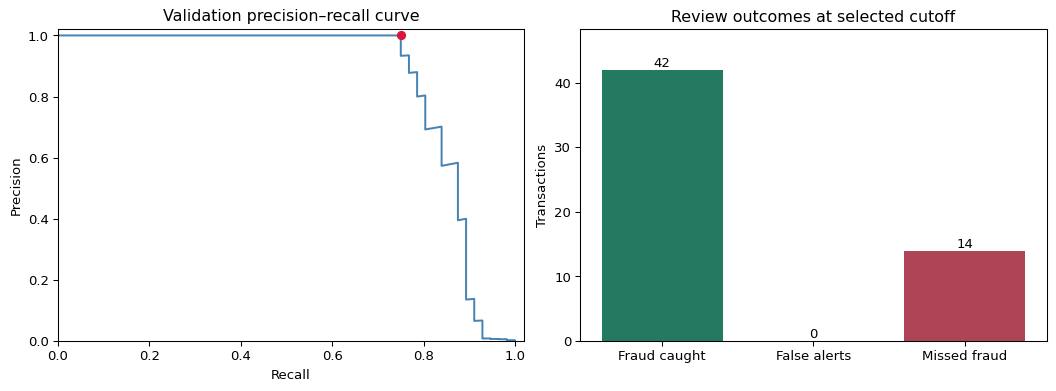

,Time,Amount,score,Class
238222,149582.000000,1.10,1.000000000,1
234574,148028.000000,0.00,0.999999881,1
223572,143434.000000,1.00,0.999999762,1
223618,143456.000000,1.00,0.999999762,1
230076,146179.000000,0.77,0.999999762,1
235634,148476.000000,0.76,0.999999285,1
226814,144808.000000,667.55,0.999999166,1
226877,144839.000000,0.00,0.999998927,1
229712,146022.000000,1.18,0.999998927,1
235644,148479.000000,122.68,0.999998689,1


In [9]:
# @title Validation dashboard
use_saved_threshold = True # @param {type:"boolean"}
custom_cutoff = 0.999 # @param {type:"number"}
cutoff = threshold if use_saved_threshold else custom_cutoff
if not 0 <= cutoff <= 1:
    raise ValueError("Enter a cutoff between 0 and 1.")

def review_summary(cut):
    # A transaction at the exact cutoff is included in the queue.
    flagged = scores >= cut
    tp = int(((labels == 1) & flagged).sum())
    fp = int(flagged.sum()) - tp
    fn = int(labels.sum()) - tp
    return {"Reviews": tp + fp, "Fraud caught": tp, "False alerts": fp, "Missed fraud": fn,
            "Precision": tp / (tp + fp) if tp + fp else np.nan, "Recall": tp / (tp + fn)}

current = review_summary(cutoff)
display(pd.DataFrame([review_summary(threshold), current], index=["Saved cutoff", "Selected cutoff"]).round(4))
print(f"Selected cutoff = {cutoff:.10f}")

fig, (pr, counts) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
pr.plot(curve_recall, curve_precision, color="steelblue")
if current["Reviews"]:
    pr.scatter(current["Recall"], current["Precision"], color="crimson", zorder=3)
pr.set(xlabel="Recall", ylabel="Precision", title="Validation precision–recall curve",
       xlim=(0, 1.02), ylim=(0, 1.02))
categories = ["Fraud caught", "False alerts", "Missed fraud"]
bars = counts.bar(categories, [current[key] for key in categories], color=["#237a61", "#df9132", "#ae4456"])
counts.bar_label(bars)
counts.margins(y=0.15)
counts.set(ylabel="Transactions", title="Review outcomes at selected cutoff")
plt.show()

# Ground truth is shown here for retrospective review.
queue = validation_rows.loc[validation_rows.score >= cutoff, ["Time", "Amount", "score", "Class"]]
display(queue.nlargest(10, "score").style.format({"score": "{:.9f}", "Amount": "{:.2f}"}))

## Evaluate once on the latest transactions
Read the precision–recall curve across thresholds and the alert counts at the selected threshold. AP weights precision by each increase in recall. Trapezoidal PR-AUC integrates the plotted curve with linear interpolation. Both are reported so the calculation is explicit.

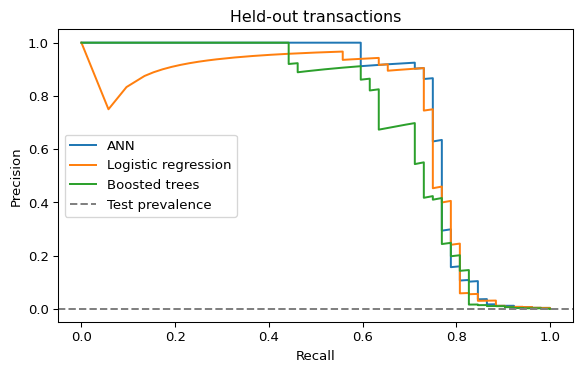

,Threshold,AP,PR-AUC,Alerts,True alerts,False alerts,Missed fraud,Precision,Recall
Model,,,,,,,,,
ANN,0.9993,0.7635,0.7631,39,36,3,16,0.9231,0.6923
Logistic regression,1.0000,0.7069,0.7104,35,33,2,19,0.9429,0.6346
Boosted trees,0.7816,0.7068,0.7058,40,33,7,19,0.8250,0.6346


In [10]:
# Use the latest window to evaluate the already selected models and cutoffs.
Xt, yt = arrays(test)
test_scores = {"ANN": ann_scores(Xt)}
for name, estimator in baselines.items():
    test_scores[name] = estimator.predict_proba(Xt)[:, 1]

rows = []
fig, ax = plt.subplots(figsize=(7, 4))
for name, scores in test_scores.items():
    # Trace the tradeoff between correct alerts (precision) and fraud coverage (recall).
    p, r, _ = precision_recall_curve(yt, scores)
    rows.append({"Model": name, "Threshold": thresholds[name], "AP": average_precision_score(yt, scores),
                 "PR-AUC": auc(r, p), **alert_counts(yt, scores, thresholds[name])})
    ax.plot(r, p, label=name)
# The fraud fraction gives a reference precision for random ranking.
ax.axhline(yt.mean(), ls="--", color="gray", label="Test prevalence")
ax.set(xlabel="Recall", ylabel="Precision", title="Held-out transactions")
ax.legend()
plt.show()
display(pd.DataFrame(rows).set_index("Model").round(4))

## Review decisions under equal capacity
Using validation only, compare the original score order with an amount-aware policy. The challenger ranks by amount within the top 2K scores, where K is the original review count. True fraud amount is the face value sent for review. It does not measure recovered funds.

In [11]:
ranked = validation_rows.assign(source_record=validation_rows.index + 1).sort_values(
    ["score", "source_record"], ascending=[False, True])
budget = int(ranked.score.ge(threshold).sum())
queues = {"Score order": ranked.head(budget),
          "Amount within high risk": ranked.head(2 * budget).sort_values(
              ["Amount", "score", "source_record"], ascending=[False, False, True]).head(budget)}
policy_rows = []
for policy, queue in queues.items():
    caught = queue[queue.Class.eq(1)]
    policy_rows.append({"Policy": policy, "Reviews": len(queue), "Frauds": len(caught),
                        "False alerts": len(queue) - len(caught), "Fraud amount": caught.Amount.sum()})
policies = pd.DataFrame(policy_rows)
display(policies)

,Policy,Reviews,Frauds,False alerts,Fraud amount
0,Score order,42,42,0,7983.85
1,Amount within high risk,42,26,16,8218.86


## Export a scored batch and audit the held-out misses
The default export includes every held-out record. For a custom batch, use the same 30 features as training. A one-based source record identifies the original CSV row even after ranking. The error audit always uses the held-out labels.

In [12]:
from datetime import datetime, timezone
from tempfile import TemporaryDirectory
from uuid import uuid4
import csv
import json
import sklearn

if incoming_csv.strip():
    with Path(incoming_csv).open(encoding="utf-8-sig", newline="") as stream:
        header = next(csv.reader(stream), [])
    if len(set(header)) != len(header):
        raise ValueError("Duplicate CSV headers.")
    batch = pd.read_csv(incoming_csv, usecols=features, dtype="float64")
    if batch.empty or not np.isfinite(batch[features].to_numpy()).all():
        raise ValueError("Scoring requires at least one row with finite numeric inputs.")
    scaled = scaler.transform(batch[features]).astype("float32")
    if not np.isfinite(scaled).all():
        raise ValueError("Input exceeds the ANN numeric range.")
    batch_scores = ann_scores(scaled)
else:
    batch, batch_scores = test, test_scores["ANN"]

scored = batch[["Time", "Amount"]].assign(source_record=batch.index + 1,
    risk_score=batch_scores.astype("float64"), send_for_review=batch_scores >= threshold)
review = scored.loc[scored.send_for_review].sort_values(["risk_score", "source_record"], ascending=[False, True])
audit = test[["Time", "Amount", "Class"]].assign(source_record=test.index + 1, risk_score=test_scores["ANN"])
misses = audit.loc[audit.Class.eq(1) & audit.risk_score.lt(threshold)].sort_values("Amount", ascending=False)
print(f"Export batch: {len(scored):,} transactions, {len(review):,} alerts")
print(f"Held-out frauds missed: {len(misses)}, totaling {misses.Amount.sum():,.2f}")
display(misses.head(5))

Export batch: 42,724 transactions, 39 alerts
Held-out frauds missed: 16, totaling 2,490.95


,Time,Amount,Class,source_record,risk_score
249239,154309.0,1096.99,1,249240,0.198263
275992,166831.0,634.30,1,275993,0.582241
245556,152802.0,357.95,1,245557,0.448366
254344,156685.0,187.11,1,254345,0.032171
280149,169351.0,77.89,1,280150,0.998867


In [13]:
# Publish completed files together under a fresh run ID.
output = project / "Artifacts" / "End-to-end runs"
output.mkdir(parents=True, exist_ok=True)
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
destination = output / run_id
with TemporaryDirectory(dir=output) as temp:
    staging = Path(temp) / "results"
    staging.mkdir()
    torch.save({"state_dict": {k: v.cpu() for k, v in best_weights.items()},
                "features": features, "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
                "threshold": threshold, "best_epoch": best_epoch,
                "architecture": "Linear(30,64) ReLU Dropout(0.2) Linear(64,32) ReLU Linear(32,1)"},
               staging / "ann.pt")
    pd.DataFrame(rows).to_csv(staging / "test_metrics.csv", index=False)
    policies.to_csv(staging / "validation_policies.csv", index=False)
    scored.to_csv(staging / "scored_transactions.csv", index=False)
    review.to_csv(staging / "review_queue.csv", index=False)
    misses.to_csv(staging / "missed_frauds.csv", index=False)
    manifest = {"run_id": run_id, "seed": SEED, "best_epoch": best_epoch,
                "ann_threshold": threshold, "batch_source": Path(incoming_csv).name if incoming_csv.strip() else "held-out replay",
                "split_sizes": [len(train), len(valid), len(test)], "time_boundaries": [float(cut1), float(cut2)],
                "torch": str(torch.__version__), "sklearn": sklearn.__version__, "numpy": np.__version__,
                "pandas": pd.__version__}
    (staging / "run.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    staging.rename(destination)
print("Saved under Artifacts / End-to-end runs /", run_id)

Saved under Artifacts / End-to-end runs / 20261121T184214Z_272d93dd
